# Capstone I: Mutual Fund Analytics
## Notebook: Exploratory Data Analysis (EDA)

**Goal:** understand the 10 cleaned datasets before modelling: what each contains, how values are distributed, and which patterns are worth pursuing.

**Sections**
1. Setup and load data
2. Dataset overview and data quality
3. Fund universe
4. NAV history
5. AUM by fund house
6. Scheme performance metrics
7. Investor transactions
8. Industry trends (SIP, category inflows, folios)
9. Portfolio holdings
10. Benchmark indices
11. Key findings

In [15]:
from pathlib import Path

# Check the notebook's current working directory
print("Current directory:", Path.cwd())

# Search for cleaned CSV files inside the current directory and subfolders
base = Path.cwd()

for file in base.rglob("*fund_master*clean*.csv"):
    print("Found:", file.resolve())


Current directory: C:\Users\Sakshi Mane
Found: C:\Users\Sakshi Mane\processed\fund_master_clean.csv
Found: C:\Users\Sakshi Mane\OneDrive\Desktop\Capstone Project\Datasets\processed\fund_master_clean.csv
Found: C:\Users\Sakshi Mane\OneDrive\Desktop\Capstone Project\data\processed\fund_master_clean.csv
Found: C:\Users\Sakshi Mane\Downloads\day2_project\day2_project\data\processed\fund_master_clean.csv
Found: C:\Users\Sakshi Mane\data\processed\fund_master_cleaned.csv


In [16]:

import warnings


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

# 1. Set the actual data folder
PROC = Path.home() / "processed"
FIG = Path.home() / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

if not PROC.exists():
    raise FileNotFoundError(f"Processed folder does not exist: {PROC}")

csv_files = sorted(PROC.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(f"No CSV files found in: {PROC}")

print("=" * 70)
print("MF ANALYTICS PLATFORM - DATA ANALYSIS")
print("=" * 70)
print("Reading from:", PROC)
print("Figures saved to:", FIG)
print("CSV files found:", len(csv_files))
print()

# 2. Load datasets
datasets = {}

for file in csv_files:
    name = file.stem
    df = pd.read_csv(file)

    # Convert columns that look like dates
    for col in df.columns:
        if any(word in col.lower() for word in ("date", "month")):
            converted = pd.to_datetime(df[col], errors="coerce")
            if converted.notna().any():
                df[col] = converted

    datasets[name] = df
    print(f"Loaded: {file.name} | Rows: {len(df):,} | Columns: {len(df.columns)}")

print("\n" + "=" * 70)
print("DATASET SUMMARIES")
print("=" * 70)

# 3. Display the first five rows of each dataset
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    display(df.head())

# 4. Dataset overview
overview = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": int(df.isnall().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    }
    for name, df in datasets.items()
])

print("\n" + "=" * 70)
print("DATA QUALITY OVERVIEW")
print("=" * 70)
display(overview)

# 5. Numeric descriptive statistics
for name, df in datasets.items():
    numeric = df.select_dtypes(include=np.number)

    if not numeric.empty:
        print(f"\n--- Numeric statistics: {name} ---")
        display(numeric.describe().round(2))




# 9. Save overview report
report_path = FIG.parent / "dataset_overview.csv"
overview.to_csv(report_path, index=False)

print("\n" + "=" * 70)
print("ANALYSIS COMPLETED")
print("=" * 70)
print("Datasets loaded:", len(datasets))
print("Overview report:", report_path)
print("Figures folder:", FIG)
print("\nGenerated files:")
for file in sorted(FIG.iterdir()):
    print("-", file.name)


MF ANALYTICS PLATFORM - DATA ANALYSIS
Reading from: C:\Users\Sakshi Mane\processed
Figures saved to: C:\Users\Sakshi Mane\reports\figures
CSV files found: 12

Loaded: aum_by_fund_house_clean.csv | Rows: 90 | Columns: 5
Loaded: benchmark_indices_clean.csv | Rows: 8,050 | Columns: 3
Loaded: category_inflows_clean.csv | Rows: 144 | Columns: 3
Loaded: cleaning_log.csv | Rows: 24 | Columns: 3
Loaded: fund_master_clean.csv | Rows: 40 | Columns: 15
Loaded: industry_folio_count_clean.csv | Rows: 21 | Columns: 6
Loaded: investor_transactions_clean.csv | Rows: 32,778 | Columns: 20
Loaded: monthly_sip_inflows_clean.csv | Rows: 48 | Columns: 7
Loaded: nav_history_clean.csv | Rows: 46,000 | Columns: 3
Loaded: portfolio_holdings_clean.csv | Rows: 322 | Columns: 8
Loaded: scheme_performance_clean.csv | Rows: 40 | Columns: 19
Loaded: validation_checks.csv | Rows: 8 | Columns: 3

DATASET SUMMARIES

--- aum_by_fund_house_clean ---


,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
0,2022-03-31,SBI Mutual Fund,6.05,605000,186
1,2022-03-31,ICICI Prudential Mutual Fund,4.65,465000,216
2,2022-03-31,HDFC Mutual Fund,4.35,435000,195
3,2022-03-31,Nippon India Mutual Fund,2.70,270000,177
4,2022-03-31,Kotak Mahindra Mutual Fund,2.70,270000,168



--- benchmark_indices_clean ---


,date,index_name,close_value
0,2022-01-03,NIFTY50,"17,492.79"
1,2022-01-04,NIFTY50,"17,689.64"
2,2022-01-05,NIFTY50,"17,835.05"
3,2022-01-06,NIFTY50,"17,878.51"
4,2022-01-07,NIFTY50,"17,759.15"



--- category_inflows_clean ---


...


--- Numeric statistics: portfolio_holdings_clean ---


,amfi_code,weight_pct,market_value_cr,current_price_inr
count,322.00,322.00,322.00,322.00
mean,"121,210.43",10.56,"1,008.85","4,080.87"
std,"14,669.38",6.06,543.83,"2,265.19"
min,"100,016.00",0.99,55.74,246.78
25%,"118,633.00",6.02,513.70,"2,081.98"
50%,"119,552.00",9.40,"1,045.67","4,139.00"
75%,"120,842.75",13.92,"1,477.50","5,914.31"
max,"149,324.00",38.18,"1,999.50","7,942.96"



--- Numeric statistics: scheme_performance_clean ---


,amfi_code,return_1yr_pct,return_3yr_pct,return_5yr_pct,benchmark_3yr_pct,alpha,beta,sharpe_ratio,sortino_ratio,std_dev_ann_pct,max_drawdown_pct,aum_crore,expense_ratio_pct,morningstar_rating
count,40.00,40.00,40.00,40.00,40.00,40.00,40.00,40.00,40.00,40.00,40.00,40.00,40.00,40.00
mean,"120,247.00",14.38,14.09,14.52,12.84,1.25,0.87,1.36,2.08,14.96,-19.20,"26,091.60",1.24,4.25
std,"14,535.00",4.88,4.62,4.45,4.74,0.45,0.22,1.48,2.20,6.67,8.82,"13,809.11",0.39,0.74
min,"100,016.00",4.26,5.14,5.43,3.96,0.51,0.22,0.80,1.03,0.50,-33.50,979.00,0.55,3.00
25%,"118,632.75",11.74,12.04,12.34,10.69,0.89,0.89,0.86,1.27,14.00,-25.06,"17,400.50",0.79,4.00
50%,"119,551.50",14.62,14.20,14.18,13.09,1.20,0.96,0.92,1.44,14.00,-20.60,"26,713.00",1.42,4.00
75%,"120,842.25",16.39,15.88,17.58,14.78,1.70,1.00,0.98,1.64,19.00,-14.26,"38,125.00",1.54,5.00
max,"149,324.00",24.93,23.39,23.80,22.16,1.98,1.04,7.68,10.37,25.00,-2.23,"49,046.00",1.64,5.00



ANALYSIS COMPLETED
Datasets loaded: 12
Overview report: C:\Users\Sakshi Mane\reports\dataset_overview.csv
Figures folder: C:\Users\Sakshi Mane\reports\figures

Generated files:
- aum_by_fund_house_clean_correlation.png
- dataset_record_counts.png
- fund_master_clean_correlation.png
- industry_folio_count_clean_correlation.png
- investor_transactions_clean_correlation.png
- missing_values_by_dataset.png
- monthly_sip_inflows_clean_correlation.png
- nav_history_clean_correlation.png
- portfolio_holdings_clean_correlation.png
- scheme_performance_clean_correlation.png


In [18]:
PROC = Path.home() / "processed"

def load(name, dates=()):
    # Support both naming conventions
    candidates = [
        PROC / f"{name}_clean.csv",
        PROC / f"{name}_cleaned.csv",
    ]

    file_path = next((p for p in candidates if p.exists()), None)

    if file_path is None:
        available = sorted(p.name for p in PROC.glob("*.csv"))
        raise FileNotFoundError(
            f"Cannot find cleaned file for '{name}'.\n"
            f"Folder: {PROC}\nAvailable files: {available}"
        )

    df = pd.read_csv(file_path)

    for col in dates:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors="coerce")
        else:
            print(f"Warning: '{col}' missing from {file_path.name}")

    print(f"Loaded {file_path.name}: {len(df):,} rows × {len(df.columns)} columns")
    return df


# 1. Load all ten datasets
fm = load("fund_master", ["launch_date"])
nav = load("nav_history", ["date"])
aum = load("aum_by_fund_house", ["date"])
sip = load("monthly_sip_inflows", ["month"])
cat_in = load("category_inflows", ["month"])
folio = load("industry_folio_count", ["month"])
perf = load("scheme_performance")
tx = load("investor_transactions", ["transaction_date"])
hold = load("portfolio_holdings", ["portfolio_date"])
bm = load("benchmark_indices", ["date"])


# 2. Check transaction columns before processing
tx_cols = [
    "investor_id", "transaction_date", "amfi_code",
    "transaction_type", "amount_inr", "state", "city",
    "city_tier", "age_group", "gender", "annual_income_lakh",
    "payment_mode", "kyc_status"
]

missing_tx = [c for c in tx_cols if c not in tx.columns]

fund_cols = [
    "amfi_code", "scheme_name", "fund_house",
    "category", "sub_category", "plan"
]
missing_fm = [c for c in fund_cols if c not in fm.columns]

if missing_tx:
    raise ValueError(f"Missing transaction columns: {missing_tx}")

if missing_fm:
    raise ValueError(f"Missing fund master columns: {missing_fm}")


# 3. Attach fund details without duplicating existing fund columns
tx = tx[tx_cols].merge(
    fm[fund_cols],
    on="amfi_code",
    how="left",
    validate="many_to_one"
)

# 4. Create monthly and signed transaction amounts
tx["month"] = tx["transaction_date"].dt.to_period("M").dt.to_timestamp()

tx["signed_amount"] = np.where(
    tx["transaction_type"].astype(str).str.strip().str.lower() == "redemption",
    -tx["amount_inr"],
    tx["amount_inr"]
)

# 5. Rupees-to-crore conversion factor
CR = 1e7

# 6. Exclude forward-filled NAV rows when the flag exists
if "is_filled" in nav.columns:
    nav_td = nav[nav["is_filled"] == 0].copy()
else:
    nav_td = nav.copy()

print("\n" + "=" * 55)
print("DATA LOADING COMPLETED")
print("=" * 55)
print("Fund master rows:", f"{len(fm):,}")
print("NAV trading-day rows:", f"{len(nav_td):,}")
print("Transactions after fund merge:", f"{len(tx):,}")
print("Transactions without matched scheme:", f"{tx['scheme_name'].isna().sum():,}")
print("Rupees per crore:", f"{CR:,.0f}")

print("\nTransaction preview:")
display(tx.head())

print("\nFund master preview:")
display(fm.head())


Loaded fund_master_clean.csv: 40 rows × 15 columns
Loaded nav_history_clean.csv: 46,000 rows × 3 columns
Loaded aum_by_fund_house_clean.csv: 90 rows × 5 columns
Loaded monthly_sip_inflows_clean.csv: 48 rows × 7 columns
Loaded category_inflows_clean.csv: 144 rows × 3 columns
Loaded industry_folio_count_clean.csv: 21 rows × 6 columns
Loaded scheme_performance_clean.csv: 40 rows × 19 columns
Loaded investor_transactions_clean.csv: 32,778 rows × 20 columns
Loaded portfolio_holdings_clean.csv: 322 rows × 8 columns
Loaded benchmark_indices_clean.csv: 8,050 rows × 3 columns

DATA LOADING COMPLETED
Fund master rows: 40
NAV trading-day rows: 46,000
Transactions after fund merge: 32,778
Transactions without matched scheme: 0
Rupees per crore: 10,000,000

Transaction preview:


,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status,scheme_name,fund_house,category,sub_category,plan,month,signed_amount
0,INV003054,2024-01-01,119092,SIP,1834,Telangana,Hyderabad,T30,56+,Female,77.10,UPI,Verified,Axis Bluechip Fund - Regular - Growth,Axis Mutual Fund,Equity,Large Cap,Regular,2024-01-01,1834
1,INV002952,2024-01-01,148567,Redemption,392882,Punjab,Amritsar,B30,18-25,Male,7.10,Cheque,Verified,Mirae Asset Large Cap Fund - Regular - Growth,Mirae Asset Mutual Fund,Equity,Large Cap,Regular,2024-01-01,-392882
2,INV003420,2024-01-01,118636,SIP,912,Haryana,Faridabad,B30,36-45,Male,47.20,Mandate,Verified,Nippon India Gilt Securities Fund - Regular - ...,Nippon India Mutual Fund,Debt,Gilt,Regular,2024-01-01,912
3,INV003436,2024-01-01,118634,SIP,1102,Maharashtra,Mumbai,T30,36-45,Female,54.40,Cheque,Pending,Nippon India Small Cap Fund - Regular - Growth,Nippon India Mutual Fund,Equity,Small Cap,Regular,2024-01-01,1102
4,INV004691,2024-01-01,119094,Lumpsum,8682,Delhi,Noida,T30,26-35,Male,14.50,Net Banking,Pending,Axis Midcap Fund - Regular - Growth,Axis Mutual Fund,Equity,Mid Cap,Regular,2024-01-01,8682



Fund master preview:


,amfi_code,fund_house,scheme_name,category,sub_category,plan,launch_date,benchmark,expense_ratio_pct,exit_load_pct,min_sip_amount,min_lumpsum_amount,fund_manager,risk_category,sebi_category_code
0,119551,SBI Mutual Fund,SBI Bluechip Fund - Regular Plan - Growth,Equity,Large Cap,Regular,2006-02-14,NIFTY 100 TRI,1.54,1.00,500,1000,Sohini Andani,Moderate,EC01
1,119552,SBI Mutual Fund,SBI Bluechip Fund - Direct Plan - Growth,Equity,Large Cap,Direct,2013-01-01,NIFTY 100 TRI,0.66,1.00,500,1000,Sohini Andani,Moderate,EC01
2,119598,SBI Mutual Fund,SBI Small Cap Fund - Regular Plan - Growth,Equity,Small Cap,Regular,2009-09-09,BSE 250 SmallCap TRI,1.43,1.00,500,1000,R. Srinivasan,Very High,EC03
3,119599,SBI Mutual Fund,SBI Small Cap Fund - Direct Plan - Growth,Equity,Small Cap,Direct,2013-01-01,BSE 250 SmallCap TRI,0.72,1.00,500,1000,R. Srinivasan,Very High,EC03
4,119120,SBI Mutual Fund,SBI Magnum Gilt Fund - Regular Plan - Growth,Debt,Gilt,Regular,2000-12-30,CRISIL Dynamic Gilt Index,0.77,0.00,500,1000,Dinesh Ahuja,Low,DC02


In [19]:
frames = {"fund_master": fm, "nav_history": nav, "aum_by_fund_house": aum, "monthly_sip_inflows": sip,
          "category_inflows": cat_in, "industry_folio_count": folio, "scheme_performance": perf,
          "investor_transactions": tx, "portfolio_holdings": hold, "benchmark_indices": bm}
overview = pd.DataFrame({
    "rows": {k: len(v) for k, v in frames.items()},
    "columns": {k: v.shape[1] for k, v in frames.items()},
    "missing_cells": {k: int(v.isna().sum().sum()) for k, v in frames.items()},
    "duplicate_rows": {k: int(v.duplicated().sum()) for k, v in frames.items()},
})
overview

,rows,columns,missing_cells,duplicate_rows
fund_master,40,15,0,0
nav_history,46000,3,0,0
aum_by_fund_house,90,5,0,0
monthly_sip_inflows,48,7,12,0
category_inflows,144,3,0,0
industry_folio_count,21,6,0,0
scheme_performance,40,19,0,0
investor_transactions,32778,20,0,0
portfolio_holdings,322,8,0,0
benchmark_indices,8050,3,0,0


In [20]:
miss = pd.concat({k: v.isna().sum() for k, v in frames.items()}).rename("missing").reset_index()
miss.columns = ["dataset", "column", "missing"]
miss = miss[miss["missing"] > 0]
print("Columns with missing values (empty means none):")
miss

Columns with missing values (empty means none):


,dataset,column,missing
28,monthly_sip_inflows,yoy_growth_pct,12


In [22]:
FIG = Path.home() / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    path = FIG / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved successfully: {path}")

print("save_fig is now defined!")


save_fig is now defined!


Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_fund_universe.png


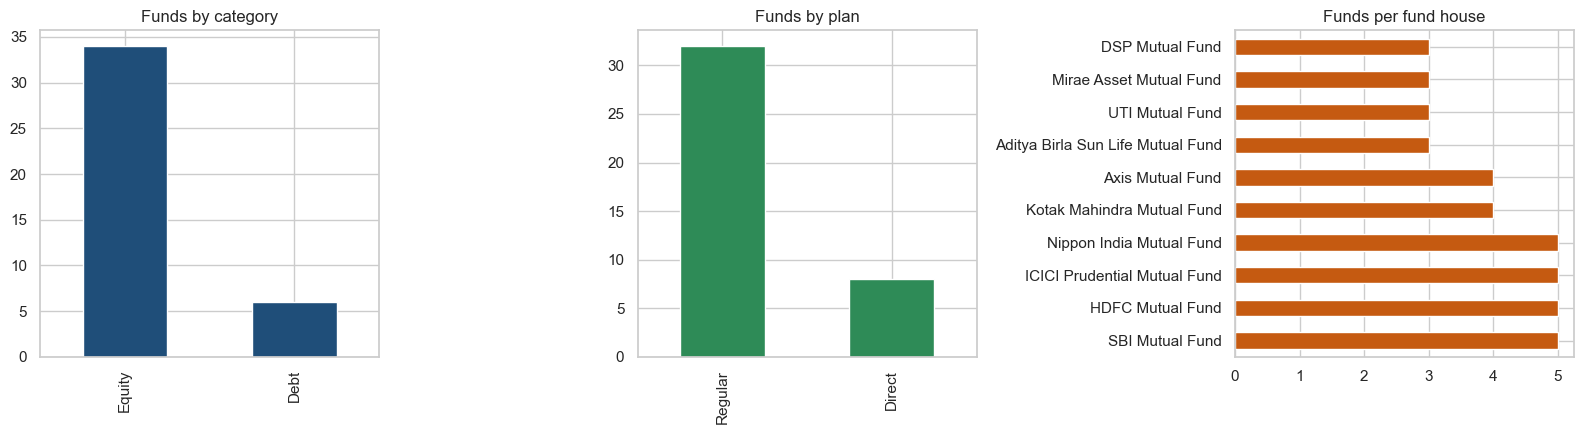

,category,sub_category,funds
0,Debt,Gilt,2
1,Debt,Liquid,3
2,Debt,Short Duration,1
3,Equity,ELSS,1
4,Equity,Flexi Cap,2
5,Equity,Index,1
6,Equity,Index/ETF,1
7,Equity,Large & Mid Cap,1
8,Equity,Large Cap,14
9,Equity,Mid Cap,7


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fm["category"].value_counts().plot.bar(ax=axes[0], color="#1F4E79", title="Funds by category")
fm["plan"].value_counts().plot.bar(ax=axes[1], color="#2E8B57", title="Funds by plan")
fm["fund_house"].value_counts().plot.barh(ax=axes[2], color="#C55A11", title="Funds per fund house")
for a in axes: a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout(); save_fig("eda_fund_universe"); plt.show()
fm.groupby(["category", "sub_category"]).size().rename("funds").reset_index()

Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_expense_ratio.png


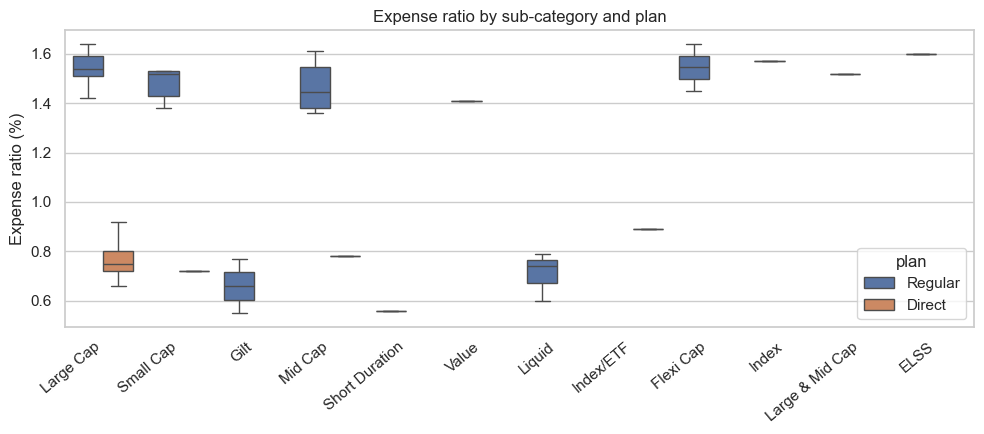

         count  mean  std  min  25%  50%  75%  max
plan                                              
Direct    8.00  0.78 0.09 0.66 0.72 0.76 0.82 0.92
Regular  32.00  1.35 0.34 0.55 1.38 1.51 1.55 1.64


In [24]:
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=fm, x="sub_category", y="expense_ratio_pct", hue="plan")
plt.xticks(rotation=40, ha="right"); plt.title("Expense ratio by sub-category and plan")
plt.ylabel("Expense ratio (%)"); plt.xlabel("")
plt.tight_layout(); save_fig("eda_expense_ratio"); plt.show()
print(fm.groupby("plan")["expense_ratio_pct"].describe().round(2))

Date range : 2022-01-03 to 2026-05-29
Funds      : 40
Rows/fund  : {'count': 40.0, 'mean': 1150.0, 'std': 0.0, 'min': 1150.0, '25%': 1150.0, '50%': 1150.0, '75%': 1150.0, 'max': 1150.0}
Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_nav_growth.png


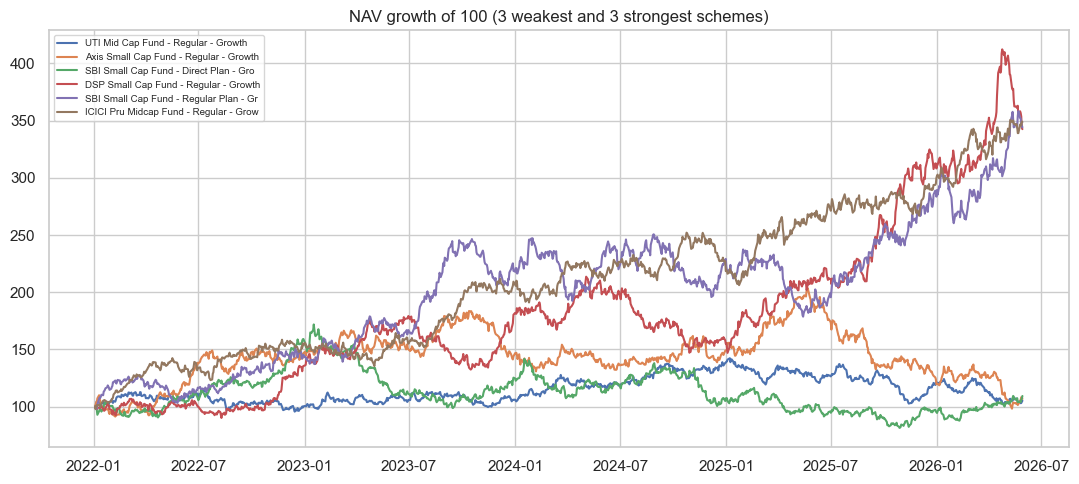

In [25]:
print("Date range :", nav_td["date"].min().date(), "to", nav_td["date"].max().date())
print("Funds      :", nav_td["amfi_code"].nunique())
print("Rows/fund  :", nav_td.groupby("amfi_code").size().describe().round(0).to_dict())

pivot = nav_td.pivot(index="date", columns="amfi_code", values="nav")
rebased = pivot / pivot.iloc[0] * 100            # every fund starts at 100
labels = fm.set_index("amfi_code")["scheme_name"]
final = rebased.iloc[-1].sort_values()
show = list(final.index[:3]) + list(final.index[-3:])   # 3 weakest and 3 strongest growth
plt.figure(figsize=(11, 5))
for code_ in show:
    plt.plot(rebased.index, rebased[code_], label=labels[code_][:38])
plt.title("NAV growth of 100 (3 weakest and 3 strongest schemes)"); plt.legend(fontsize=7)
plt.tight_layout(); save_fig("eda_nav_growth"); plt.show()

Daily return, all funds pooled:
count   45,960.00
mean         0.06
std          1.03
min         -5.81
25%         -0.50
50%          0.03
75%          0.63
max          6.47
dtype: float64
Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_daily_return_dist.png


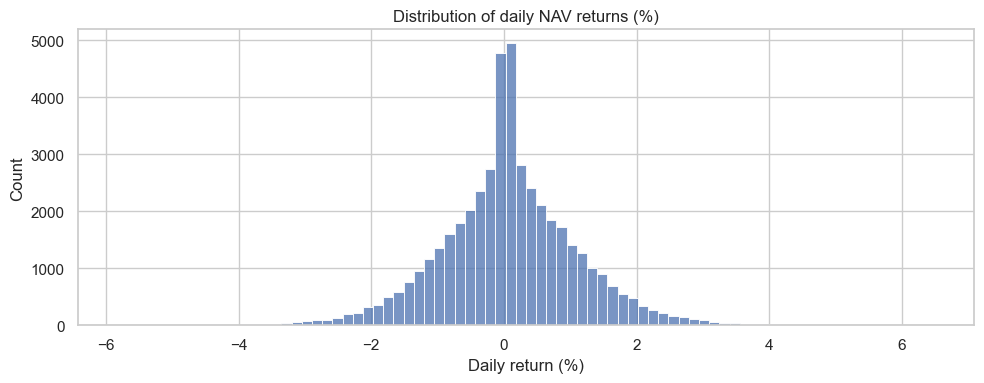

In [26]:
rets = pivot.pct_change().dropna(how="all")
print("Daily return, all funds pooled:")
print((rets.stack() * 100).describe().round(3))
plt.figure(figsize=(10, 4))
sns.histplot(rets.stack() * 100, bins=80)
plt.title("Distribution of daily NAV returns (%)"); plt.xlabel("Daily return (%)")
plt.tight_layout(); save_fig("eda_daily_return_dist"); plt.show()

Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_aum_by_house.png


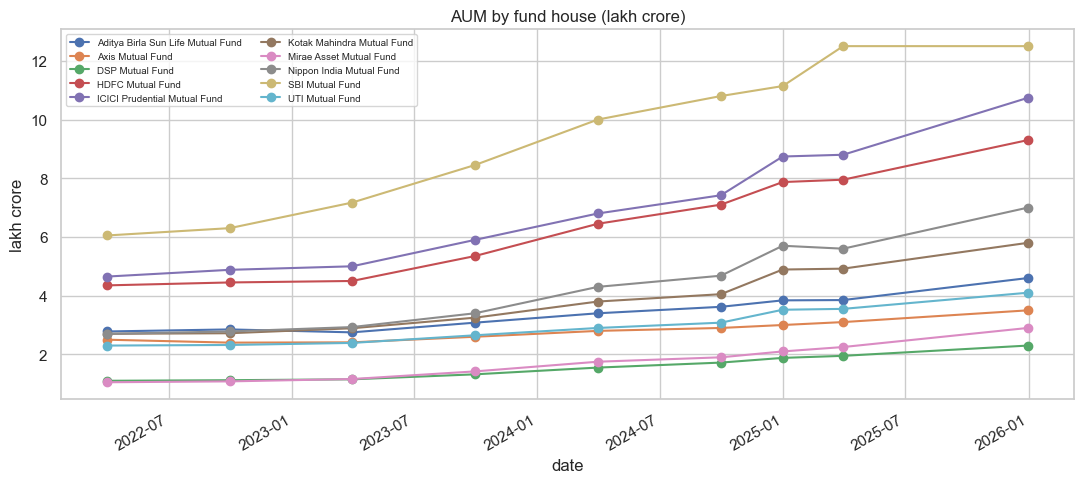

Latest reporting date: 2025-12-31


,fund_house,aum_lakh_crore,num_schemes,share_pct
80,SBI Mutual Fund,12.50,186,19.92
81,ICICI Prudential Mutual Fund,10.74,216,17.12
82,HDFC Mutual Fund,9.30,195,14.82
83,Nippon India Mutual Fund,7.00,177,11.16
84,Kotak Mahindra Mutual Fund,5.80,168,9.24
85,Aditya Birla Sun Life Mutual Fund,4.60,199,7.33
87,UTI Mutual Fund,4.10,142,6.53
86,Axis Mutual Fund,3.50,95,5.58
88,Mirae Asset Mutual Fund,2.90,56,4.62
89,DSP Mutual Fund,2.30,88,3.67


In [27]:
aum_pivot = aum.pivot(index="date", columns="fund_house", values="aum_lakh_crore")
aum_pivot.plot(figsize=(11, 5), marker="o")
plt.title("AUM by fund house (lakh crore)"); plt.ylabel("lakh crore"); plt.legend(fontsize=7, ncol=2)
plt.tight_layout(); save_fig("eda_aum_by_house"); plt.show()

latest = aum[aum["date"] == aum["date"].max()].sort_values("aum_crore", ascending=False)
latest["share_pct"] = latest["aum_crore"] / latest["aum_crore"].sum() * 100
print("Latest reporting date:", latest["date"].iloc[0].date())
latest[["fund_house", "aum_lakh_crore", "num_schemes", "share_pct"]]

Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_top_schemes_aum.png


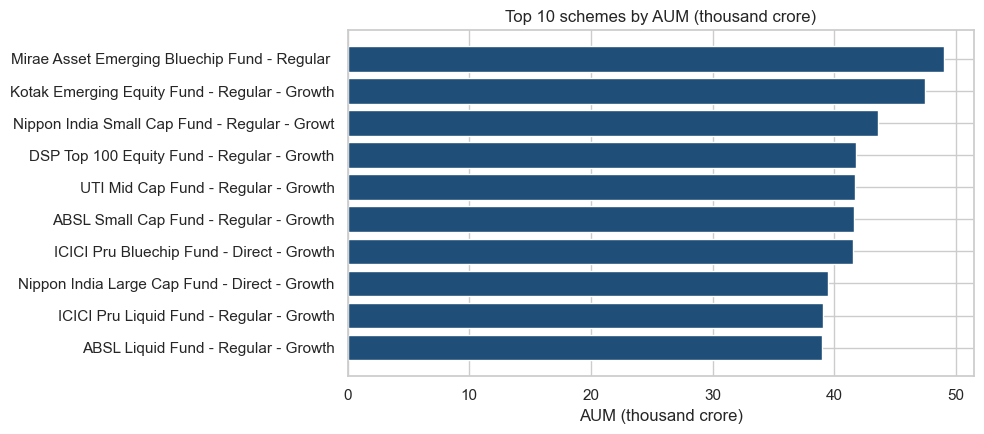

In [28]:
top_schemes = perf.nlargest(10, "aum_crore")[["scheme_name", "fund_house", "aum_crore"]]
plt.figure(figsize=(10, 4.5))
plt.barh(top_schemes["scheme_name"].str[:45][::-1], top_schemes["aum_crore"][::-1] / 1e3, color="#1F4E79")
plt.title("Top 10 schemes by AUM (thousand crore)"); plt.xlabel("AUM (thousand crore)")
plt.tight_layout(); save_fig("eda_top_schemes_aum"); plt.show()

In [29]:
metrics = ["return_1yr_pct", "return_3yr_pct", "return_5yr_pct", "alpha", "beta", "sharpe_ratio", "sortino_ratio",
           "std_dev_ann_pct", "max_drawdown_pct", "expense_ratio_pct", "aum_crore", "morningstar_rating"]
perf[metrics].describe().T[["count", "mean", "std", "min", "50%", "max"]]

,count,mean,std,min,50%,max
return_1yr_pct,40.00,14.38,4.88,4.26,14.62,24.93
return_3yr_pct,40.00,14.09,4.62,5.14,14.21,23.39
return_5yr_pct,40.00,14.52,4.45,5.43,14.19,23.80
alpha,40.00,1.25,0.45,0.51,1.21,1.98
beta,40.00,0.87,0.22,0.22,0.96,1.04
sharpe_ratio,40.00,1.36,1.48,0.80,0.93,7.68
sortino_ratio,40.00,2.08,2.20,1.03,1.44,10.37
std_dev_ann_pct,40.00,14.96,6.67,0.50,14.00,25.00
max_drawdown_pct,40.00,-19.20,8.82,-33.50,-20.60,-2.23
expense_ratio_pct,40.00,1.24,0.39,0.55,1.42,1.64


Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_performance_distributions.png


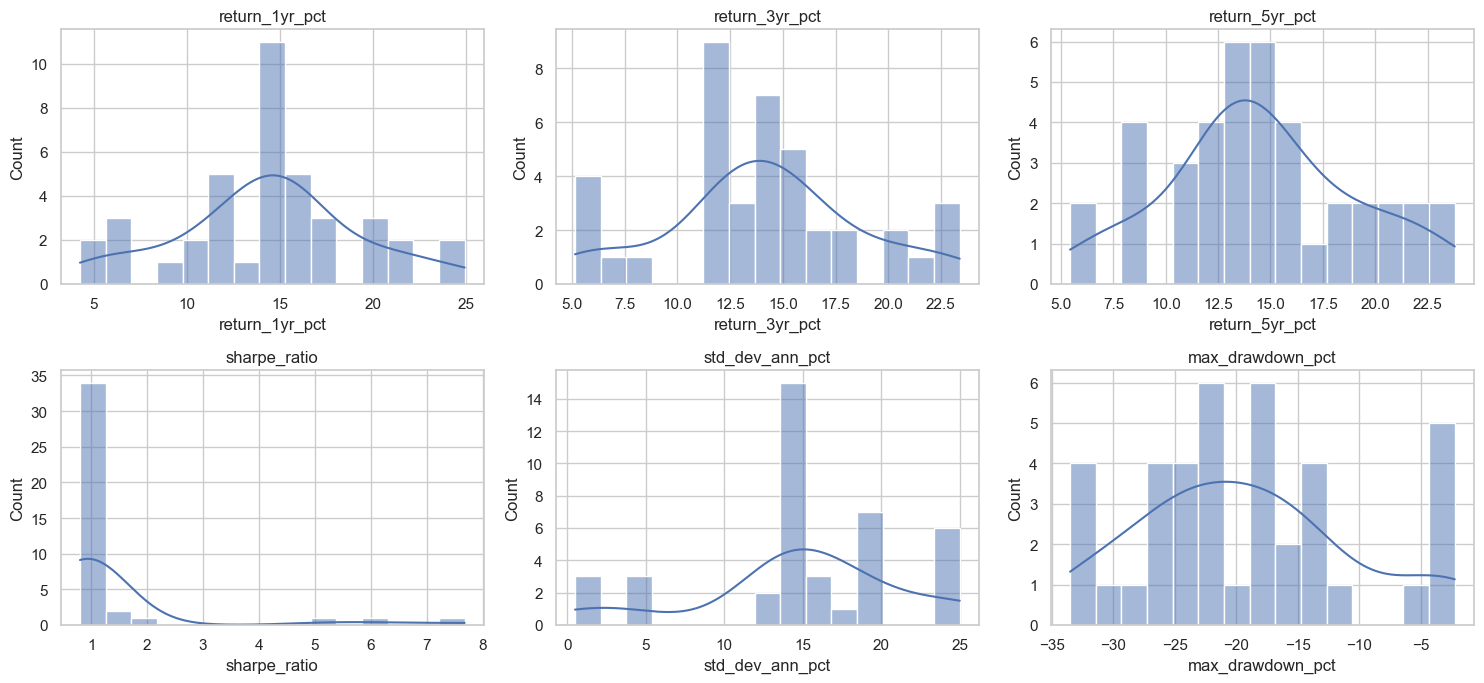

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), ["return_1yr_pct", "return_3yr_pct", "return_5yr_pct", "sharpe_ratio", "std_dev_ann_pct", "max_drawdown_pct"]):
    sns.histplot(perf[c], bins=15, kde=True, ax=ax); ax.set_title(c)
plt.tight_layout(); save_fig("eda_performance_distributions"); plt.show()

Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_performance_correlation.png


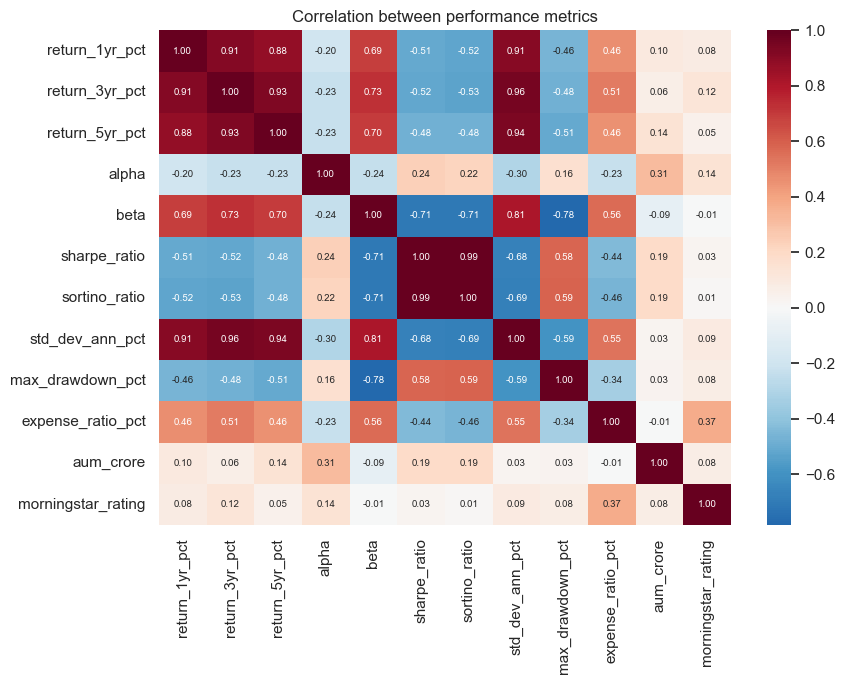

In [31]:
plt.figure(figsize=(9, 7))
sns.heatmap(perf[metrics].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Correlation between performance metrics")
plt.tight_layout(); save_fig("eda_performance_correlation"); plt.show()

,count,total_cr,average
transaction_type,,,
Lumpsum,8095,206.00,"254,456.00"
Redemption,4967,124.50,"250,558.80"
SIP,19716,21.70,"11,018.10"


Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_transaction_mix.png


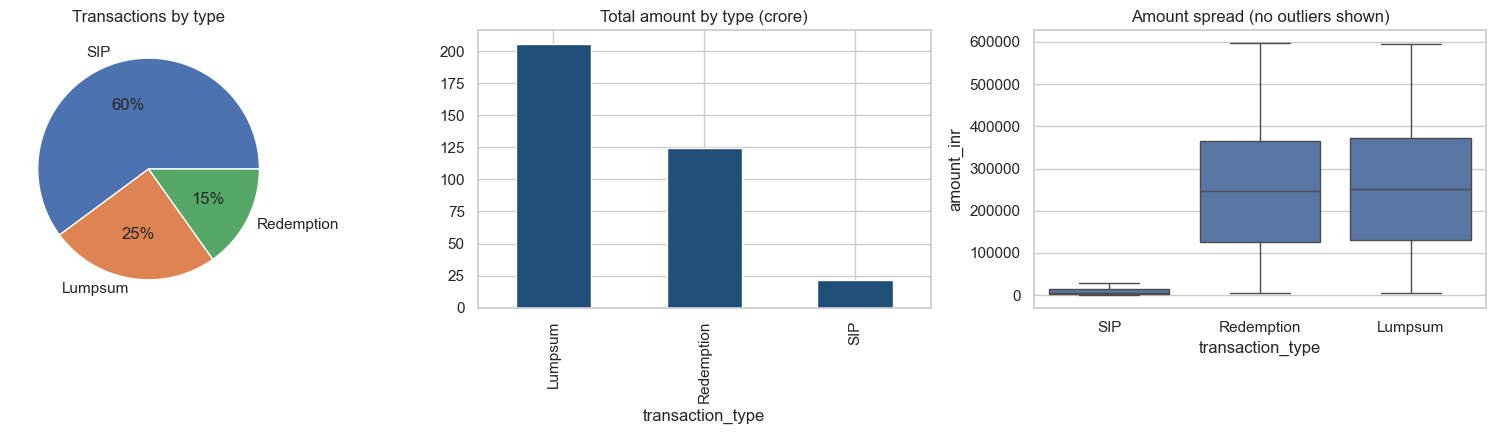

In [32]:
by_type = tx.groupby("transaction_type")["amount_inr"].agg(count="count", total_cr=lambda s: s.sum() / CR, average="mean").round(1)
display(by_type)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
tx["transaction_type"].value_counts().plot.pie(ax=axes[0], autopct="%1.0f%%", title="Transactions by type"); axes[0].set_ylabel("")
tx.groupby("transaction_type")["amount_inr"].sum().div(CR).plot.bar(ax=axes[1], color="#1F4E79", title="Total amount by type (crore)")
sns.boxplot(data=tx, x="transaction_type", y="amount_inr", showfliers=False, ax=axes[2]); axes[2].set_title("Amount spread (no outliers shown)")
plt.tight_layout(); save_fig("eda_transaction_mix"); plt.show()

Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_monthly_transactions.png


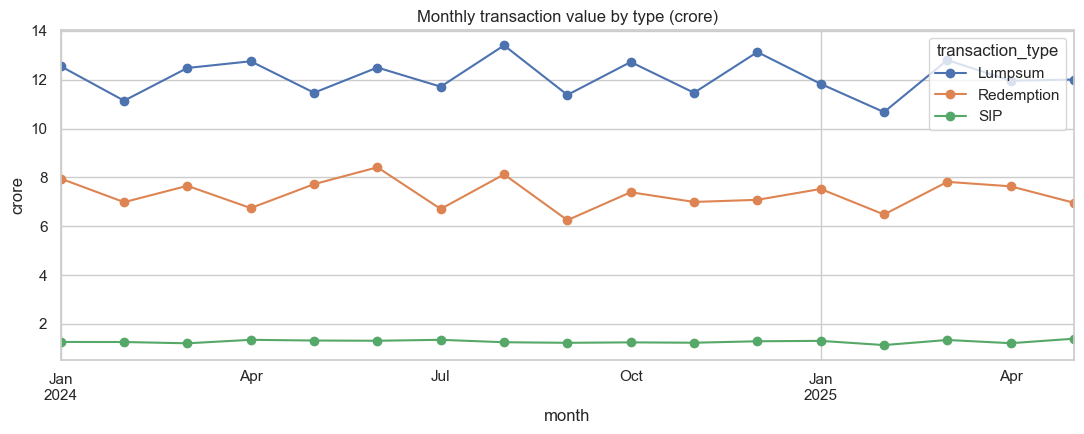

Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_monthly_net_flow.png


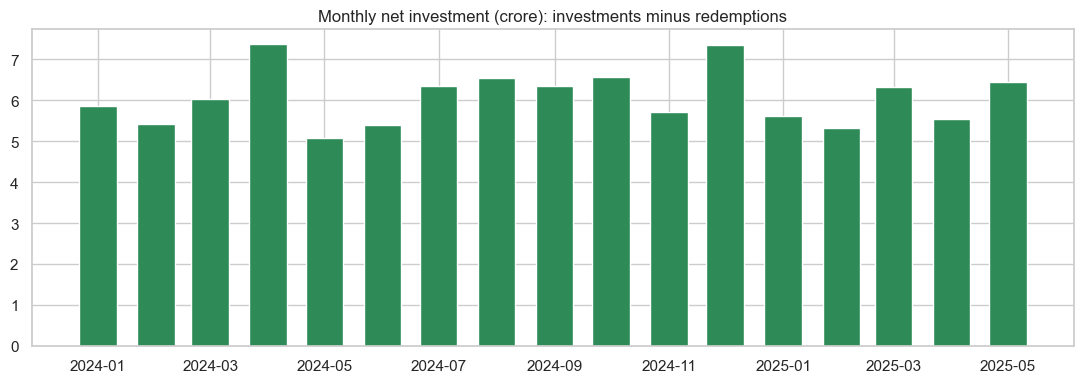

In [33]:
monthly = tx.groupby(["month", "transaction_type"])["amount_inr"].sum().div(CR).unstack()
monthly.plot(figsize=(11, 4.5), marker="o")
plt.title("Monthly transaction value by type (crore)"); plt.ylabel("crore")
plt.tight_layout(); save_fig("eda_monthly_transactions"); plt.show()

net = tx.groupby("month")["signed_amount"].sum().div(CR)
plt.figure(figsize=(11, 4))
plt.bar(net.index, net.values, width=20, color=np.where(net.values >= 0, "#2E8B57", "#C0392B"))
plt.title("Monthly net investment (crore): investments minus redemptions")
plt.tight_layout(); save_fig("eda_monthly_net_flow"); plt.show()

Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_investor_profile.png


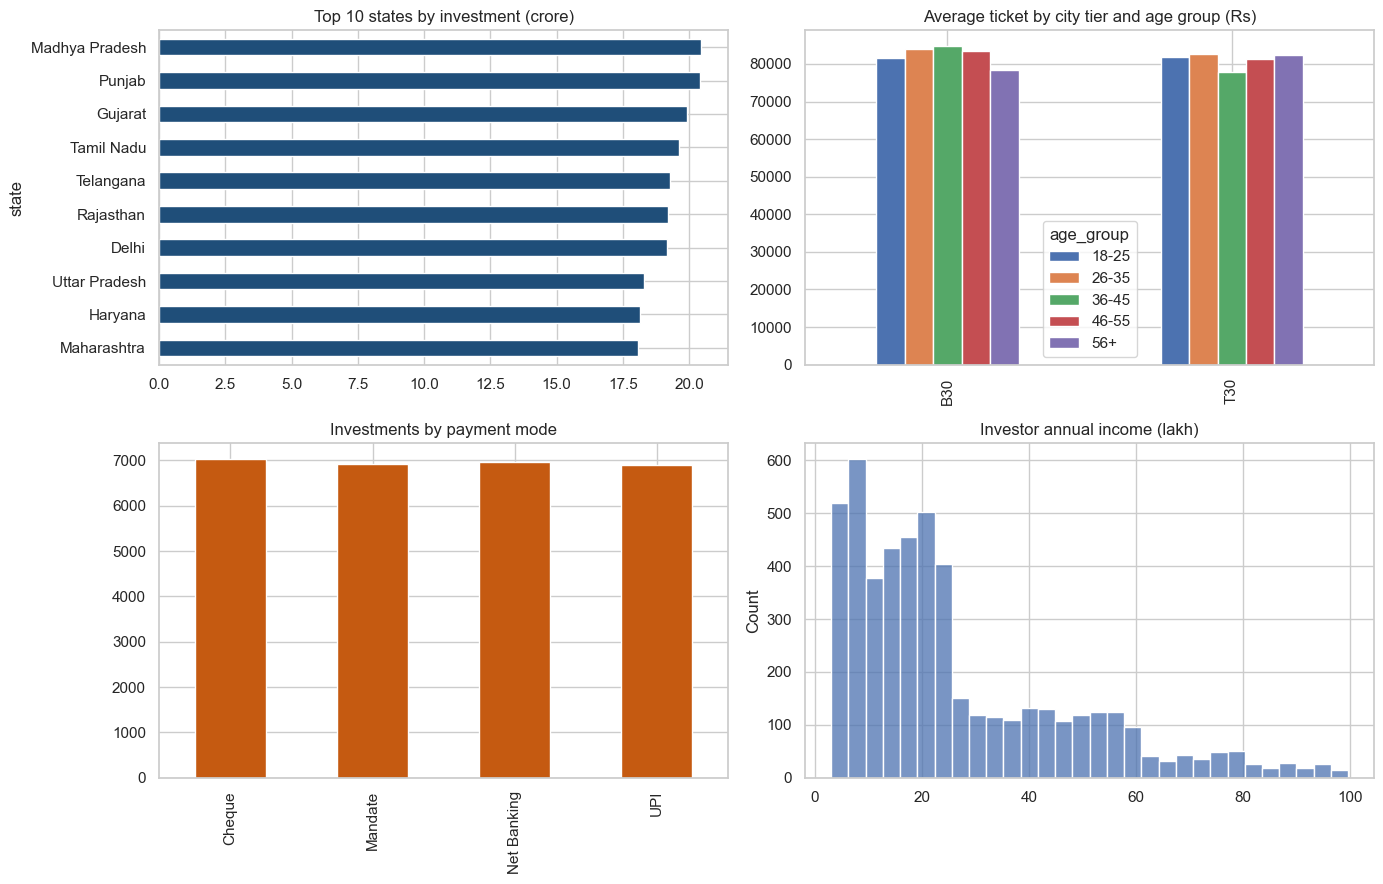

Unique investors: 5,000
KYC status: {'Verified': 92.0, 'Pending': 8.0}


In [34]:
invest = tx[tx["transaction_type"] != "Redemption"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
invest.groupby("state")["amount_inr"].sum().div(CR).nlargest(10).sort_values().plot.barh(ax=axes[0, 0], color="#1F4E79", title="Top 10 states by investment (crore)")
invest.groupby(["city_tier", "age_group"])["amount_inr"].mean().unstack().plot.bar(ax=axes[0, 1], title="Average ticket by city tier and age group (Rs)")
invest.groupby("payment_mode")["amount_inr"].count().plot.bar(ax=axes[1, 0], color="#C55A11", title="Investments by payment mode")
sns.histplot(tx.drop_duplicates("investor_id")["annual_income_lakh"], bins=30, ax=axes[1, 1]); axes[1, 1].set_title("Investor annual income (lakh)")
for a in axes.ravel(): a.set_xlabel("")
plt.tight_layout(); save_fig("eda_investor_profile"); plt.show()
print("Unique investors:", f"{tx['investor_id'].nunique():,}")
print("KYC status:", tx["kyc_status"].value_counts(normalize=True).mul(100).round(1).to_dict())

Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_industry_sip.png


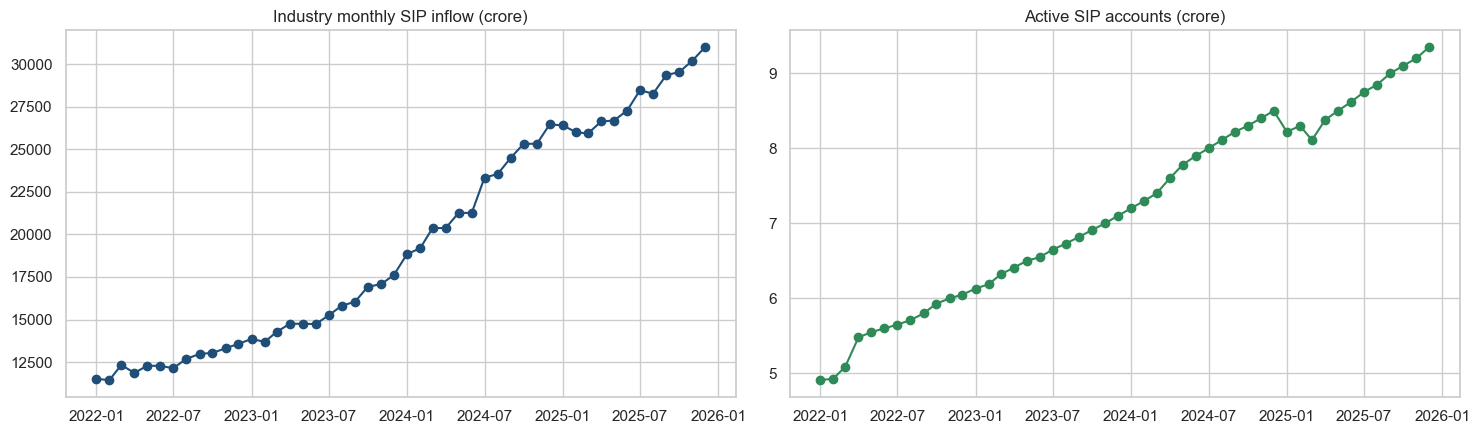

SIP inflow: Rs 11,517 crore -> 31,002 crore


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(sip["month"], sip["sip_inflow_crore"], marker="o", color="#1F4E79"); axes[0].set_title("Industry monthly SIP inflow (crore)")
axes[1].plot(sip["month"], sip["active_sip_accounts_crore"], marker="o", color="#2E8B57"); axes[1].set_title("Active SIP accounts (crore)")
plt.tight_layout(); save_fig("eda_industry_sip"); plt.show()
print("SIP inflow: Rs", f"{sip['sip_inflow_crore'].iloc[0]:,.0f}", "crore ->", f"{sip['sip_inflow_crore'].iloc[-1]:,.0f}", "crore")

Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_category_inflow_heatmap.png


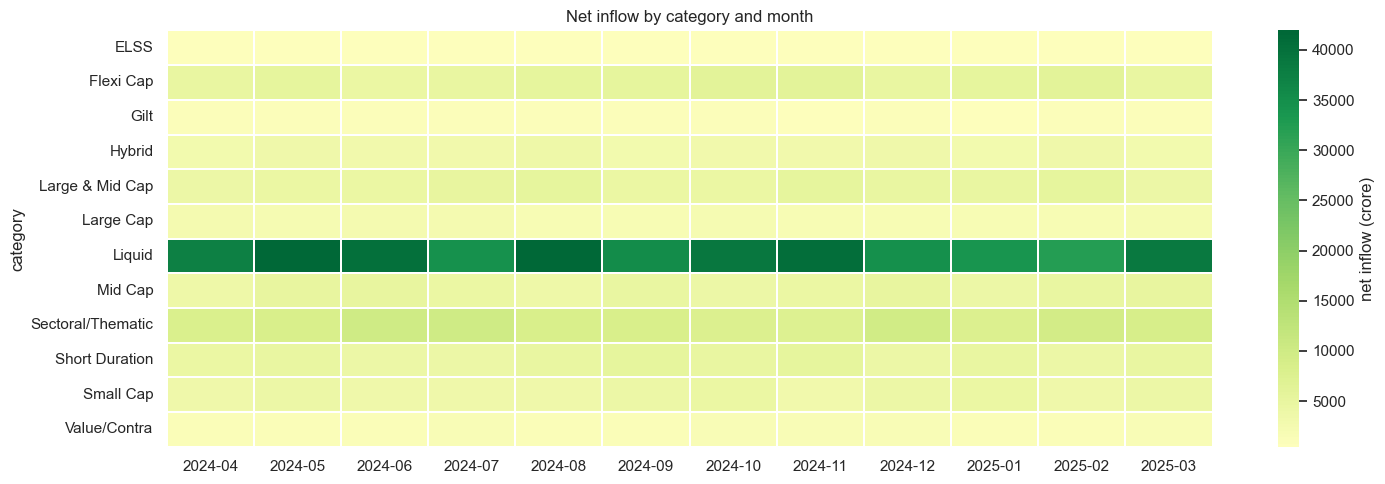

Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_folio_count.png


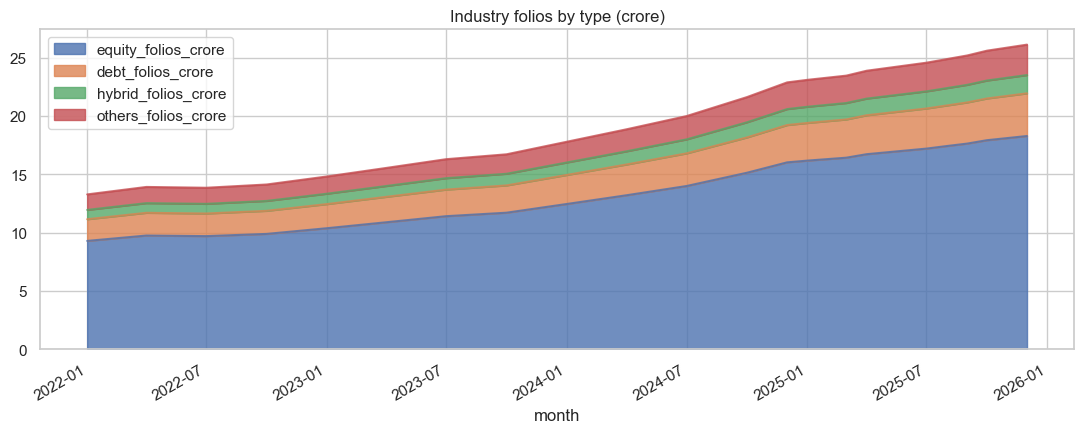

In [36]:
heat = cat_in.pivot(index="category", columns="month", values="net_inflow_crore")
heat.columns = heat.columns.strftime("%Y-%m")
plt.figure(figsize=(15, 5))
sns.heatmap(heat, cmap="RdYlGn", center=0, linewidths=0.2, cbar_kws={"label": "net inflow (crore)"})
plt.title("Net inflow by category and month"); plt.xlabel("")
plt.tight_layout(); save_fig("eda_category_inflow_heatmap"); plt.show()

folio_cols = [c for c in folio.columns if c.endswith("_folios_crore") and c != "total_folios_crore"]
folio.set_index("month")[folio_cols].plot.area(figsize=(11, 4.5), alpha=0.8)
plt.title("Industry folios by type (crore)")
plt.tight_layout(); save_fig("eda_folio_count"); plt.show()

Portfolio date: 2025-12-31 | schemes with holdings: 34
Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_holdings.png


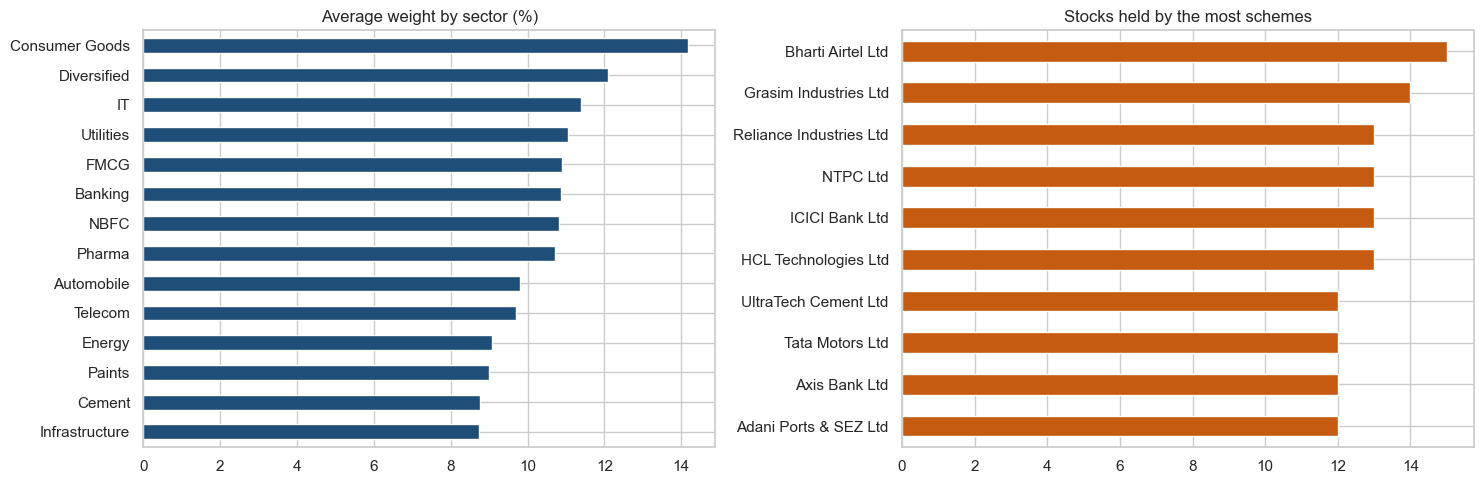

In [37]:
print("Portfolio date:", hold["portfolio_date"].max().date(), "| schemes with holdings:", hold["amfi_code"].nunique())
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
hold.groupby("sector")["weight_pct"].mean().sort_values().plot.barh(ax=axes[0], color="#1F4E79", title="Average weight by sector (%)")
hold.groupby("stock_name")["amfi_code"].nunique().nlargest(10).sort_values().plot.barh(ax=axes[1], color="#C55A11", title="Stocks held by the most schemes")
for a in axes: a.set_ylabel("")
plt.tight_layout(); save_fig("eda_holdings"); plt.show()

Saved successfully: C:\Users\Sakshi Mane\reports\figures\eda_benchmarks.png


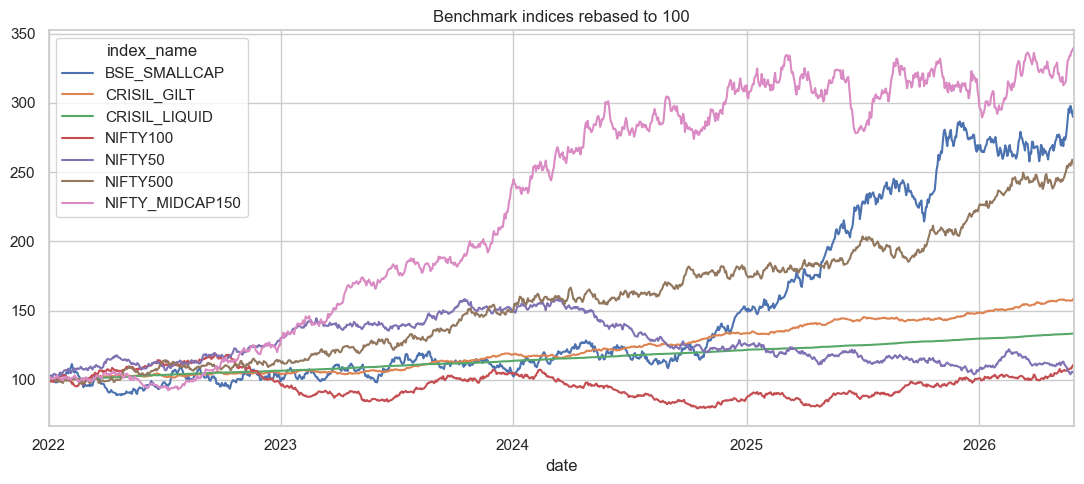

,total return since start (%)
index_name,
BSE_SMALLCAP,195.10
CRISIL_GILT,58.70
CRISIL_LIQUID,33.50
NIFTY100,10.80
NIFTY50,5.90
NIFTY500,154.00
NIFTY_MIDCAP150,237.00


In [38]:
bm_p = bm.pivot(index="date", columns="index_name", values="close_value")
(bm_p / bm_p.iloc[0] * 100).plot(figsize=(11, 5))
plt.title("Benchmark indices rebased to 100")
plt.tight_layout(); save_fig("eda_benchmarks"); plt.show()
(bm_p.iloc[-1] / bm_p.iloc[0] - 1).mul(100).round(1).rename("total return since start (%)").to_frame()

In [41]:
net_total = tx["signed_amount"].sum() / CR
sip_share = (tx["transaction_type"] == "SIP").mean() * 100
top_state = invest.groupby("state")["amount_inr"].sum().idxmax()
direct, regular = fm.groupby("plan")["expense_ratio_pct"].mean()[["Direct", "Regular"]]
corr_3y = perf[["aum_crore", "return_3yr_pct"]].corr(method="spearman").iloc[0, 1]
latest_house = latest.iloc[0]

findings = [
    f"The fund universe has {len(fm)} schemes from {fm['fund_house'].nunique()} fund houses ({(fm['category'] == 'Equity').sum()} equity, {(fm['category'] == 'Debt').sum()} debt).",
    f"Direct plans cost {direct:.2f}% a year on average against {regular:.2f}% for Regular plans, a gap of {regular - direct:.2f} percentage points.",
    f"{latest_house['fund_house']} is the largest fund house with {latest_house['aum_lakh_crore']:.2f} lakh crore AUM ({latest_house['share_pct']:.0f}% of the 10 houses).",
    f"Transactions total {len(tx):,}; SIPs are {sip_share:.0f}% of them. Net investment (investments minus redemptions) is Rs {net_total:,.0f} crore.",
    f"{top_state} is the top state by investment.",
    f"Industry monthly SIP inflow rose from Rs {sip['sip_inflow_crore'].iloc[0]:,.0f} crore to Rs {sip['sip_inflow_crore'].iloc[-1]:,.0f} crore.",
    f"Scheme size and 3-year return are weakly related (Spearman rho = {corr_3y:.2f}), so bigger schemes are not automatically better performers.",
]
for f in findings:
    print("-", f)

- The fund universe has 40 schemes from 10 fund houses (34 equity, 6 debt).
- Direct plans cost 0.78% a year on average against 1.35% for Regular plans, a gap of 0.57 percentage points.
- SBI Mutual Fund is the largest fund house with 12.50 lakh crore AUM (20% of the 10 houses).
- Transactions total 32,778; SIPs are 60% of them. Net investment (investments minus redemptions) is Rs 103 crore.
- Madhya Pradesh is the top state by investment.
- Industry monthly SIP inflow rose from Rs 11,517 crore to Rs 31,002 crore.
- Scheme size and 3-year return are weakly related (Spearman rho = 0.10), so bigger schemes are not automatically better performers.
